# 01. Exploratory Data Analysis & Data Preprocessing

**Lead Responsible**: Pehesara W.A.C (`IT24103684`)  
**Module**: IT3091 – Machine Learning | Group 2026-AI-15  
**Track**: Industry Explorer Track  

---

## Objectives
1. Ingest the Kaggle E-Commerce 2023 proxy dataset and inspect schema structure.
2. Handle missing values (e.g. `days_since_prior_order` for first orders) and duplicates.
3. Analyze basket size distributions, product co-occurrence frequencies, and department breakdowns.
4. Export cleaned, optimized parquet files into `data/processed/`.

In [18]:
import sys
from pathlib import Path

# Add project root to sys.path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import clean_ecommerce_data, create_stratified_sample
from src.utils import setup_plot_style, save_figure

setup_plot_style()
print("Environment initialized successfully.")

Environment initialized successfully.


In [19]:
import sys
from pathlib import Path

# Resolve project root dynamically
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

# Core scientific libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing modules
from sklearn.preprocessing import (
    StandardScaler, 
    RobustScaler, 
    MinMaxScaler,
    LabelEncoder,
    OrdinalEncoder
)

# Project modular imports
from src.data_loader import load_raw_dataset
from src.utils import setup_plot_style, save_figure, export_summary_table

# Apply corporate publication theme (300 DPI, clean fonts, whitegrid)
setup_plot_style()

print(f"[OK] Python Interpreter : {sys.executable}")
print(f"[OK] Project Root       : {PROJECT_ROOT}")

[OK] Python Interpreter : E:\Git_Projects\Supermarket\.venv\Scripts\python.exe
[OK] Project Root       : E:\Git_Projects\Supermarket


## 1. Data Ingestion & Diagnostic Health Audit
We load the raw transactional log (`ECommerce_consumer_behaviour.csv`) and compute key health indicators:
row counts, attribute types, memory footprint, and distinct entity cardinalities.

In [20]:
RAW_FILE = "ECommerce_consumer_behaviour.csv"
df_raw = load_raw_dataset(RAW_FILE)

total_rows, total_cols = df_raw.shape
initial_mem = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)

print("DATASET INTEGRITY & HEALTH DIAGNOSTIC")
print(f"Total Transaction Rows : {total_rows:,}")
print(f"Total Column Features  : {total_cols}")
print(f"Initial Memory In RAM  : {initial_mem:.2f} MB")
print("Column Cardinalities & Types:")
for col in df_raw.columns:
    print(f"  - {col:<24}: {df_raw[col].nunique():>8,} unique | {df_raw[col].dtype}")

[Loading Dataset] -> ECommerce_consumer_behaviour.csv (Source: E:\Git_Projects\Supermarket\data\raw)
DATASET INTEGRITY & HEALTH DIAGNOSTIC
Total Transaction Rows : 2,019,501
Total Column Features  : 12
Initial Memory In RAM  : 228.11 MB
Column Cardinalities & Types:
  - order_id                :  200,000 unique | int64
  - user_id                 :  105,273 unique | int64
  - order_number            :      100 unique | int64
  - order_dow               :        7 unique | int64
  - order_hour_of_day       :       24 unique | int64
  - days_since_prior_order  :       31 unique | float64
  - product_id              :      134 unique | int64
  - add_to_cart_order       :      137 unique | int64
  - reordered               :        2 unique | int64
  - department_id           :       21 unique | int64
  - department              :       21 unique | str
  - product_name            :      134 unique | str


## 2. Duplicate Detection & Granular Integrity

In [21]:
# 1. Full row duplicates
full_dups = df_raw.duplicated().sum()

# 2. Cart position collisions
cart_collisions = df_raw.duplicated(subset=["order_id", "add_to_cart_order"]).sum()

# 3. Repeated product purchases within the same order
intra_order_repeats = df_raw.duplicated(subset=["order_id", "product_id"]).sum()

print("--- Duplicate Audit Results ---")
print(f"1. Exact Full-Row Duplicates           : {full_dups}")
print(f"2. Cart Position Index Collisions      : {cart_collisions}")
print(f"3. Intra-Order Product Repeats         : {intra_order_repeats:,} ({(intra_order_repeats/len(df_raw))*100:.2f}%)")

df_clean = df_raw.copy()

# Resolution: In retail, repeated products in one order represent Quantity.
# Compute item_quantity_in_basket permanently across all 2.01M rows:
df_clean["item_quantity_in_basket"] = (
    df_clean.groupby(["order_id", "product_id"], observed=False)["product_id"]
    .transform("count")
    .astype("uint8")
)
print("'item_quantity_in_basket' computed permanently across all rows.")

--- Duplicate Audit Results ---
1. Exact Full-Row Duplicates           : 0
2. Cart Position Index Collisions      : 0
3. Intra-Order Product Repeats         : 566,385 (28.05%)
'item_quantity_in_basket' computed permanently across all rows.


## 3. Structural Missing Value Diagnostic
An audit of null values reveals that missing values only exist in `days_since_prior_order`.  
We test the hypothesis that missing values are **Missing Not At Random (MNAR)** and correspond precisely to each customer's initial acquisition order (`order_number == 1`).

In [22]:
null_counts = df_clean.isnull().sum()
print("Null Values by Column:")
print(null_counts[null_counts > 0])

first_order_nulls = df_clean[df_clean["order_number"] == 1]["days_since_prior_order"].isna().sum()
subsequent_nulls = df_clean[df_clean["order_number"] > 1]["days_since_prior_order"].isna().sum()
total_nulls = df_clean["days_since_prior_order"].isna().sum()

print("\n--- Structural Null Verification ---")
print(f"Total nulls in 'days_since_prior_order' : {total_nulls:,}")
print(f"Nulls on initial orders (order_number=1): {first_order_nulls:,} ({(first_order_nulls/total_nulls)*100:.1f}%)")
print(f"Nulls on repeat orders (order_number > 1): {subsequent_nulls:,} (0.0%)")

assert first_order_nulls == total_nulls, "Anomaly: unexpected nulls in repeat orders!"
print("\n All nulls are structurally explained by initial baseline orders.")

Null Values by Column:
days_since_prior_order    124342
dtype: int64

--- Structural Null Verification ---
Total nulls in 'days_since_prior_order' : 124,342
Nulls on initial orders (order_number=1): 124,342 (100.0%)
Nulls on repeat orders (order_number > 1): 0 (0.0%)

 All nulls are structurally explained by initial baseline orders.


In [23]:
# Treatment: Create boolean flag and impute baseline with sentinel value (-1)
df_clean["is_first_order"] = df_clean["days_since_prior_order"].isna().astype("bool")
df_clean["days_since_prior_order"] = df_clean["days_since_prior_order"].fillna(-1)
print(" Created 'is_first_order' flag and set initial baseline gap to -1.")

 Created 'is_first_order' flag and set initial baseline gap to -1.


## 4. Outlier Analysis & Extreme Basket Detection (IQR Method)

In [24]:
# Calculate basket size (items per order)
df_clean["basket_size"] = (
    df_clean.groupby("order_id", observed=False)["product_id"]
    .transform("count")
)

order_baskets = df_clean.drop_duplicates(subset=["order_id"])["basket_size"]
q1 = order_baskets.quantile(0.25)
q3 = order_baskets.quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

outlier_orders = order_baskets[order_baskets > upper_bound]
pct_outliers = (len(outlier_orders) / len(order_baskets)) * 100

print(f"IQR Upper Threshold : > {upper_bound:.1f} items")
print(f"Outlier Orders Count: {len(outlier_orders):,} ({pct_outliers:.2f}% of orders)")

# Permanent Winsorization Capping:
IQR_CAP = int(np.ceil(upper_bound))  # 28 items
df_clean["basket_size_capped"] = np.clip(df_clean["basket_size"], a_min=1, a_max=IQR_CAP).astype("uint8")

print(f" Applied Winsorization: Max basket size permanently capped at {IQR_CAP} items in 'basket_size_capped'.")

IQR Upper Threshold : > 27.5 items
Outlier Orders Count: 6,589 (3.29% of orders)
 Applied Winsorization: Max basket size permanently capped at 28 items in 'basket_size_capped'.


## 5. Skewness Assessment & Log Transformation

In [25]:
skew_before = df_clean["basket_size"].skew()

# Vectorized log transformation across all 2,019,501 rows
df_clean["basket_size_log"] = np.log1p(df_clean["basket_size"])
skew_after = df_clean["basket_size_log"].skew()

print(f"Original Basket Size Skewness : {skew_before:.3f} (Heavy right-skew)")
print(f"Log-Transformed Skewness      : {skew_after:.3f} (Normalized distribution)")
print("'basket_size_log' permanently added across all rows.")

Original Basket Size Skewness : 1.496 (Heavy right-skew)
Log-Transformed Skewness      : -0.384 (Normalized distribution)
'basket_size_log' permanently added across all rows.


## 6. Feature Scaling Comparison (`StandardScaler` vs. `RobustScaler` vs. `MinMaxScaler`)

In [26]:
# Scaling benchmark on valid repeat orders
sample_scale = (
    df_clean.query("days_since_prior_order >= 0")[["basket_size", "order_number", "days_since_prior_order"]]
    .sample(10000, random_state=42)
)

scaler_std = StandardScaler()
scaler_rob = RobustScaler()
scaler_minmax = MinMaxScaler()

scaled_std = scaler_std.fit_transform(sample_scale)
scaled_rob = scaler_rob.fit_transform(sample_scale)
scaled_minmax = scaler_minmax.fit_transform(sample_scale)

df_scale_compare = pd.DataFrame({
    "Raw Basket Size": sample_scale["basket_size"],
    "StandardScaler": scaled_std[:, 0],
    "RobustScaler": scaled_rob[:, 0],
    "MinMaxScaler": scaled_minmax[:, 0]
})
print("Scaler Comparison Benchmark (Sample):")
display(df_scale_compare.describe().round(3))

Scaler Comparison Benchmark (Sample):


,Raw Basket Size,StandardScaler,RobustScaler,MinMaxScaler
count,10000.000,10000.000,10000.000,10000.000
mean,15.716,0.000,0.143,0.136
std,9.477,1.000,0.790,0.088
min,1.000,-1.553,-1.083,0.000
25%,9.000,-0.709,-0.417,0.074
50%,14.000,-0.181,0.000,0.120
75%,21.000,0.558,0.583,0.185
max,109.000,9.843,7.917,1.000


In [27]:
# PERMANENT FEATURE SCALING APPLIED ACROSS ALL 2,019,501 ROWS OF df_clean
scaler_full = RobustScaler()

df_clean["basket_size_scaled"] = scaler_full.fit_transform(df_clean[["basket_size_capped"]]).astype("float32")
df_clean["order_number_scaled"] = scaler_full.fit_transform(df_clean[["order_number"]]).astype("float32")

# Scale days_since_prior_order for valid repeat orders, assigning baseline orders 0
valid_mask = df_clean["days_since_prior_order"] >= 0
scaled_days = np.zeros(len(df_clean), dtype="float32")
scaled_days[valid_mask] = scaler_full.fit_transform(df_clean.loc[valid_mask, ["days_since_prior_order"]]).flatten()
df_clean["days_since_prior_scaled"] = scaled_days

print("\n 'basket_size_scaled', 'order_number_scaled', 'days_since_prior_scaled' permanently added to df_clean.")


 'basket_size_scaled', 'order_number_scaled', 'days_since_prior_scaled' permanently added to df_clean.


[Exported Figure] -> reports\figures\00_preprocessing_scalers_comparison.png


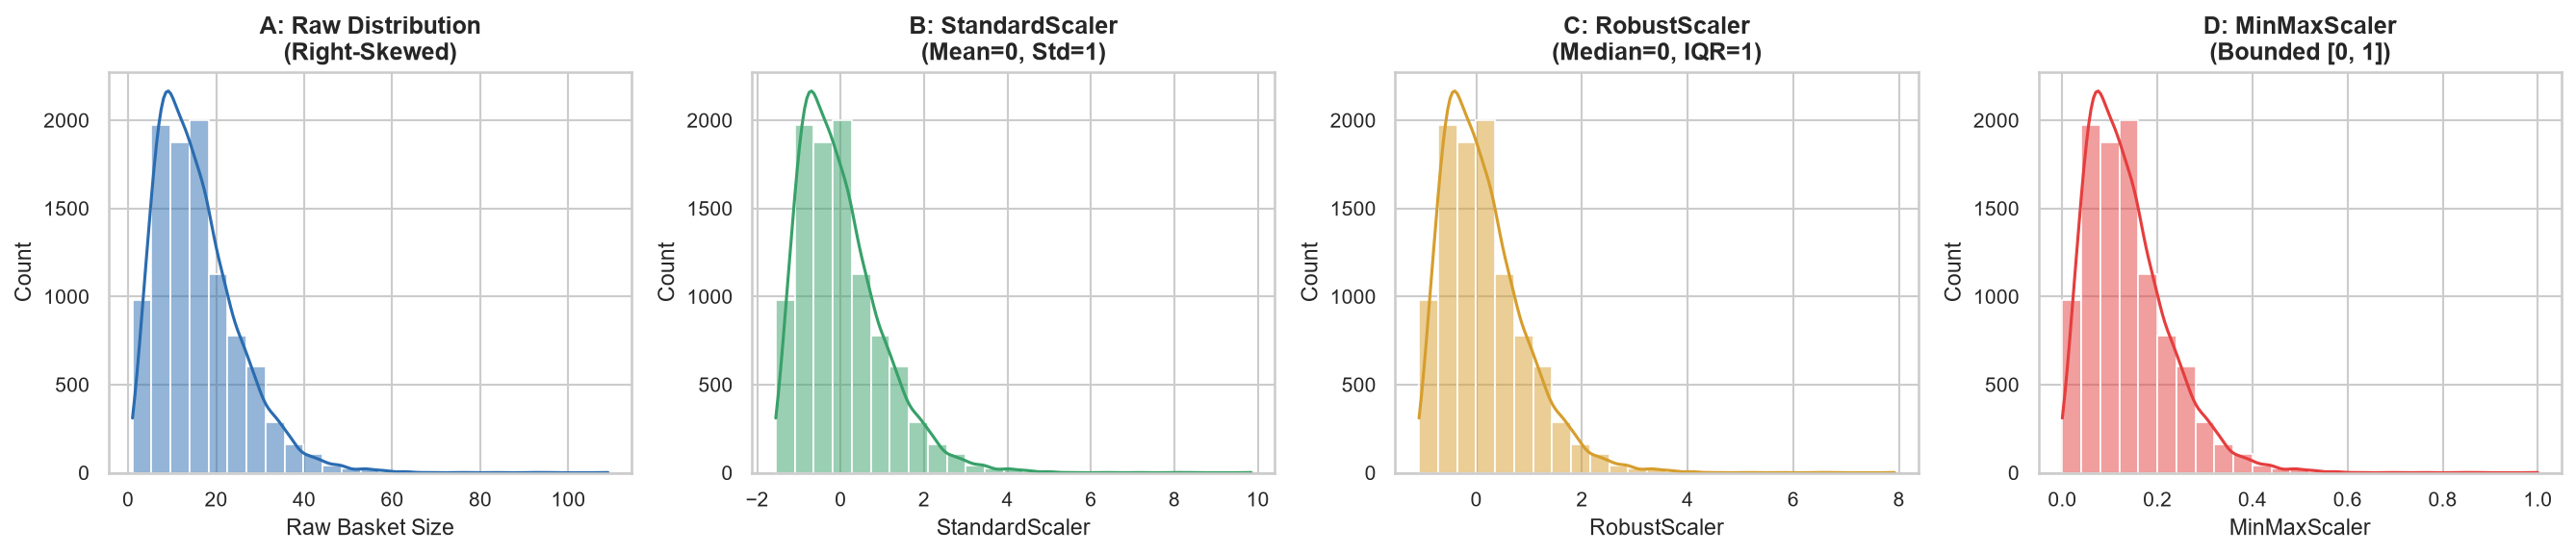

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

sns.histplot(df_scale_compare["Raw Basket Size"], bins=25, kde=True, ax=axes[0], color="#2b6cb0")
axes[0].set_title("A: Raw Distribution\n(Right-Skewed)", fontweight="bold")

sns.histplot(df_scale_compare["StandardScaler"], bins=25, kde=True, ax=axes[1], color="#38a169")
axes[1].set_title("B: StandardScaler\n(Mean=0, Std=1)", fontweight="bold")

sns.histplot(df_scale_compare["RobustScaler"], bins=25, kde=True, ax=axes[2], color="#d69e2e")
axes[2].set_title("C: RobustScaler\n(Median=0, IQR=1)", fontweight="bold")

sns.histplot(df_scale_compare["MinMaxScaler"], bins=25, kde=True, ax=axes[3], color="#e53e3e")
axes[3].set_title("D: MinMaxScaler\n(Bounded [0, 1])", fontweight="bold")

plt.tight_layout()
save_figure(fig, "00_preprocessing_scalers_comparison.png")
plt.show()

## 7. Categorical Encoding Pipeline
We implement 4 industry-standard encoding strategies:
1. **Ordinal Encoding**: Chronological time slots (`Morning=0`, `Afternoon=1`, `Evening=2`, `Night=3`).
2. **Frequency Encoding**: Mapping macro retail departments to their overall shopping frequency proportion.
3. **Label Encoding**: Integer ID mapping for categorical models.
4. **Day Mapping**: Translating numerical integers (`0–6`) to human-readable day names.

In [29]:
# 1. Day of week mapping (0=Sunday to 6=Saturday)
dow_map = {
    0: "Sunday", 1: "Monday", 2: "Tuesday",
    3: "Wednesday", 4: "Thursday", 5: "Friday", 6: "Saturday"
}
df_clean["order_day_name"] = df_clean["order_dow"].map(dow_map).astype("category")

# 2. Operational time-of-day slots
def get_time_slot(hour: int) -> str:
    if 6 <= hour < 12:
        return "Morning (06-11)"
    elif 12 <= hour < 17:
        return "Afternoon (12-16)"
    elif 17 <= hour < 22:
        return "Evening (17-21)"
    else:
        return "Night (22-05)"

df_clean["order_time_slot"] = df_clean["order_hour_of_day"].apply(get_time_slot).astype("category")

# 3. Ordinal Encoding for time slots
time_order = [["Morning (06-11)", "Afternoon (12-16)", "Evening (17-21)", "Night (22-05)"]]
df_clean["order_time_slot_ordinal"] = OrdinalEncoder(categories=time_order).fit_transform(df_clean[["order_time_slot"]]).astype("uint8")

# 4. Frequency Encoding for Department
dept_freq_map = df_clean["department"].value_counts(normalize=True).to_dict()
df_clean["dept_frequency_enc"] = df_clean["department"].map(dept_freq_map).astype("float32")

# 5. Label Encoding for Department
df_clean["dept_label_enc"] = LabelEncoder().fit_transform(df_clean["department"]).astype("uint8")

print(" Ordinal, Frequency, and Label encodings added to df_clean.")


 Ordinal, Frequency, and Label encodings added to df_clean.


## 8. Memory Optimization via Type Downcasting
To allow fast in-memory analytics across 2.01M records, we downcast 64-bit numerical types to their minimum valid unsigned sizes and convert text strings to categoricals.

In [30]:
initial_mem_mb = df_clean.memory_usage(deep=True).sum() / (1024 ** 2)

# Downcasting map
dtype_map = {
    "order_id": "uint32",
    "user_id": "uint32",
    "order_number": "uint8",
    "order_dow": "uint8",
    "order_hour_of_day": "uint8",
    "days_since_prior_order": "int8",
    "product_id": "uint16",
    "add_to_cart_order": "uint8",
    "reordered": "uint8",
    "department_id": "uint8",
    "basket_size": "uint8"
}

for col, dtype in dtype_map.items():
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype(dtype)

# Convert high-repetition strings to category
df_clean["department"] = df_clean["department"].astype("category")
df_clean["product_name"] = df_clean["product_name"].astype("category")

# Free memory
del df_raw
import gc
gc.collect()

final_mem_mb = df_clean.memory_usage(deep=True).sum() / (1024 ** 2)
reduction_pct = (1 - (final_mem_mb / initial_mem_mb)) * 100

print(f"Initial Memory  : {initial_mem_mb:.2f} MB")
print(f"Optimized Memory: {final_mem_mb:.2f} MB")
print(f"RAM Reclaimed   : {reduction_pct:.1f}% without any loss of data precision!")

Initial Memory  : 303.23 MB
Optimized Memory: 100.15 MB
RAM Reclaimed   : 67.0% without any loss of data precision!


## 9. Strategic Exploratory Visualizations
We now generate 6 publication-ready figures to answer key supermarket merchandising questions. All plots are automatically exported at 300 DPI to `reports/figures/`.

Top 15 Categories Volume: 1,086,150 of 2,019,501 items (53.8% of all store sales)


findfont: Failed to find font weight medium for Arial, now using 400.


[Exported Figure] -> reports\figures\01_top_products_distribution.png


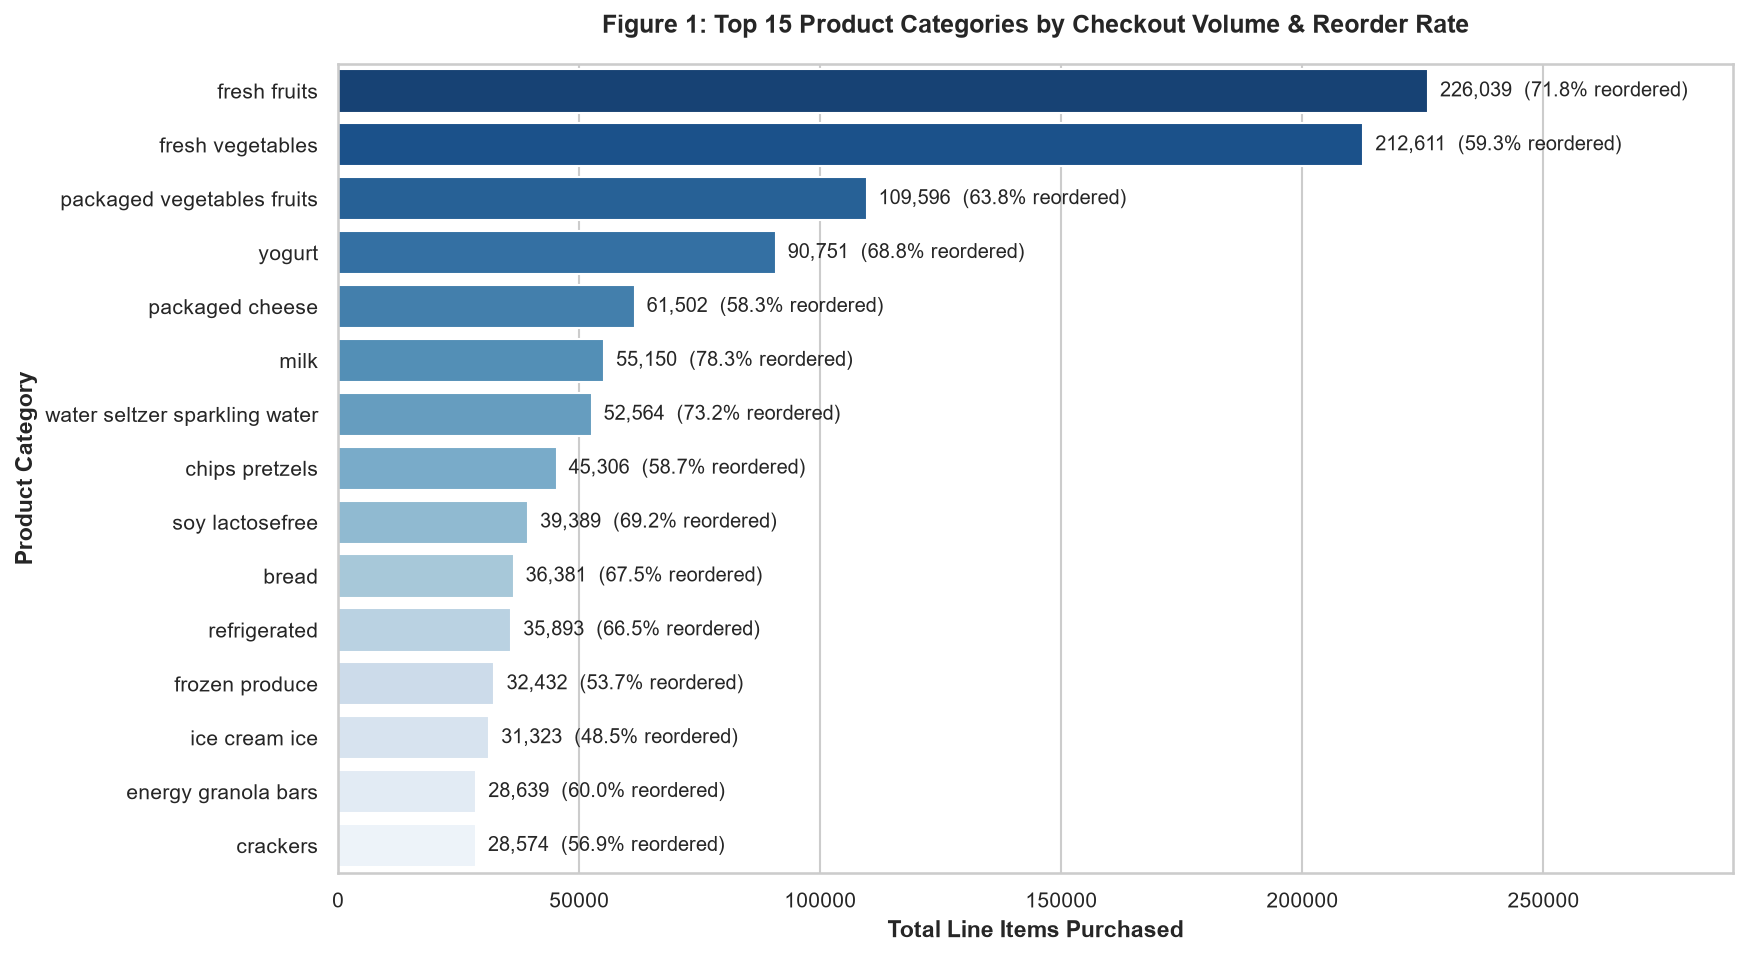

In [31]:
prod_agg = (
    df_clean.groupby("product_name", observed=False)
    .agg(volume=("order_id", "count"), reorder_rate=("reordered", "mean"))
    .sort_values(by="volume", ascending=False)
    .head(15)
    .reset_index()
)

# Cast categorical to string so Seaborn only plots these 15 products
prod_agg["product_name"] = prod_agg["product_name"].astype(str)

# Calculate volume share of total store transactions
total_store_volume = len(df_clean)
top15_volume = prod_agg["volume"].sum()
top15_share_pct = (top15_volume / total_store_volume) * 100
print(f"Top 15 Categories Volume: {top15_volume:,} of {total_store_volume:,} items ({top15_share_pct:.1f}% of all store sales)")

fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(
    data=prod_agg, 
    x="volume", 
    y="product_name", 
    hue="product_name",
    palette="Blues_r", 
    legend=False,
    ax=ax
)

for i, row in prod_agg.iterrows():
    vol = int(row["volume"])
    rate = float(row["reorder_rate"]) * 100
    ax.text(
        vol + 2500, i,
        f"{vol:,}  ({rate:.1f}% reordered)",
        va="center", fontsize=9.5, fontweight="medium"
    )

ax.set_title("Figure 1: Top 15 Product Categories by Checkout Volume & Reorder Rate", pad=15)
ax.set_xlabel("Total Line Items Purchased", fontweight="bold")
ax.set_ylabel("Product Category", fontweight="bold")
ax.set_xlim(0, prod_agg["volume"].max() * 1.28)

save_figure(fig, "01_top_products_distribution.png")
plt.show()

C:\Users\PC\AppData\Local\Temp\ipykernel_20236\612930527.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dept_agg, y="department", x="volume", palette="crest", ax=ax1)
C:\Users\PC\AppData\Local\Temp\ipykernel_20236\612930527.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dept_agg, y="department", x="reorder_rate", palette="viridis", ax=ax2)


[Exported Figure] -> reports\figures\02_department_volume_and_reorder_rate.png


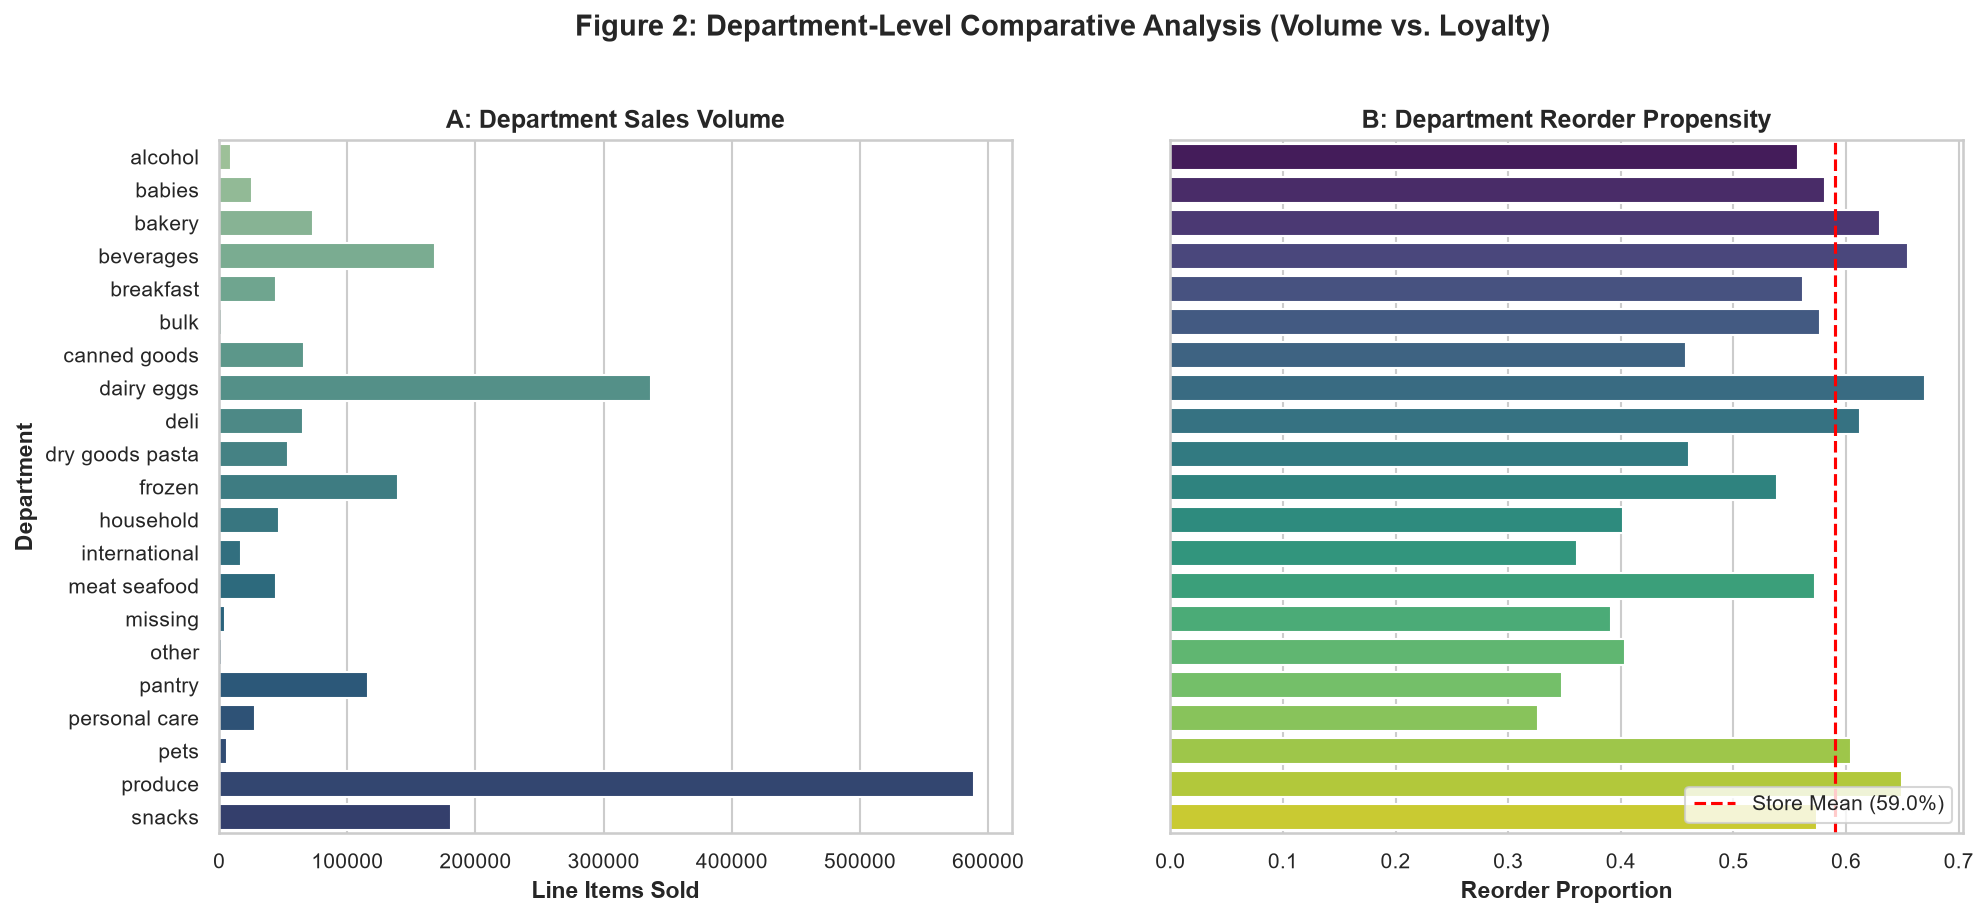

In [32]:
dept_agg = (
    df_clean.groupby("department", observed=False)
    .agg(volume=("order_id", "count"), reorder_rate=("reordered", "mean"))
    .sort_values(by="volume", ascending=False)
    .reset_index()
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

sns.barplot(data=dept_agg, y="department", x="volume", palette="crest", ax=ax1)
ax1.set_title("A: Department Sales Volume", fontweight="bold")
ax1.set_xlabel("Line Items Sold", fontweight="bold")
ax1.set_ylabel("Department", fontweight="bold")

avg_reorder = df_clean["reordered"].mean()
sns.barplot(data=dept_agg, y="department", x="reorder_rate", palette="viridis", ax=ax2)
ax2.axvline(avg_reorder, color="red", linestyle="--", label=f"Store Mean ({avg_reorder*100:.1f}%)")
ax2.set_title("B: Department Reorder Propensity", fontweight="bold")
ax2.set_xlabel("Reorder Proportion", fontweight="bold")
ax2.set_ylabel("")
ax2.legend(loc="lower right")

fig.suptitle("Figure 2: Department-Level Comparative Analysis (Volume vs. Loyalty)", y=1.02, fontsize=14, fontweight="bold")
save_figure(fig, "02_department_volume_and_reorder_rate.png")
plt.show()

[Exported Figure] -> reports\figures\03_customer_shopping_heatmap.png


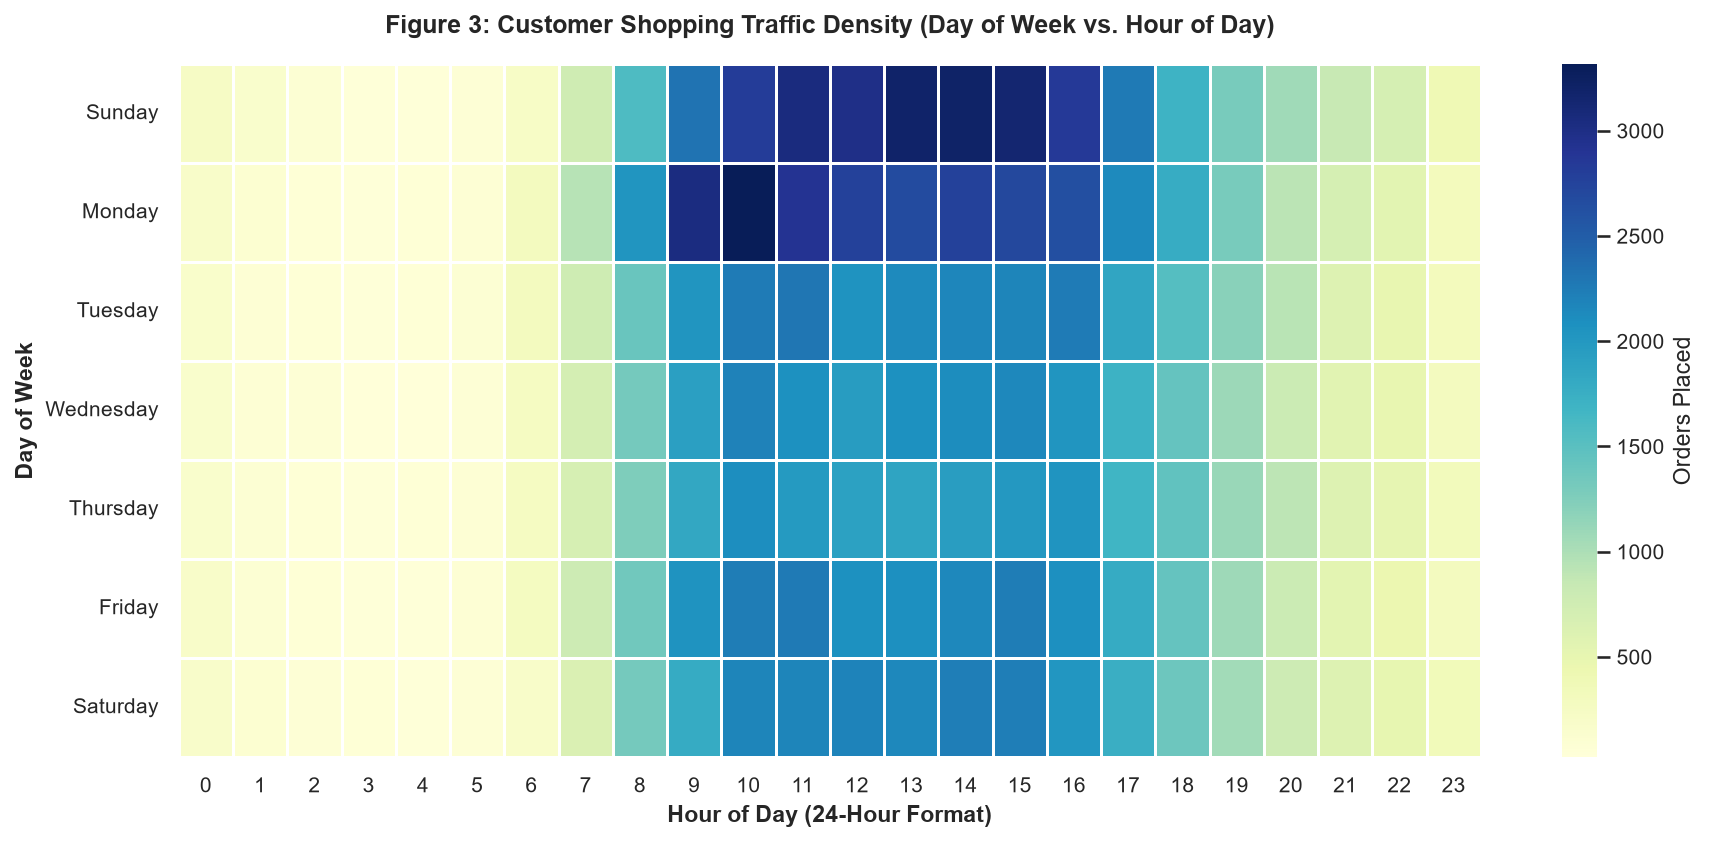

In [33]:
traffic_pivot = (
    df_clean.drop_duplicates(subset=["order_id"])
    .pivot_table(
        index="order_day_name",
        columns="order_hour_of_day",
        values="order_id",
        aggfunc="count",
        observed=False
    )
    .reindex(["Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"])
)

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(traffic_pivot, cmap="YlGnBu", linewidths=0.5, cbar_kws={"label": "Orders Placed"}, ax=ax)
ax.set_title("Figure 3: Customer Shopping Traffic Density (Day of Week vs. Hour of Day)", pad=15)
ax.set_xlabel("Hour of Day (24-Hour Format)", fontweight="bold")
ax.set_ylabel("Day of Week", fontweight="bold")

save_figure(fig, "03_customer_shopping_heatmap.png")
plt.show()


C:\Users\PC\AppData\Local\Temp\ipykernel_20236\3683723797.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=valid_intervals, palette="mako", ax=ax)


[Exported Figure] -> reports\figures\04_reorder_interval_cyclicity.png


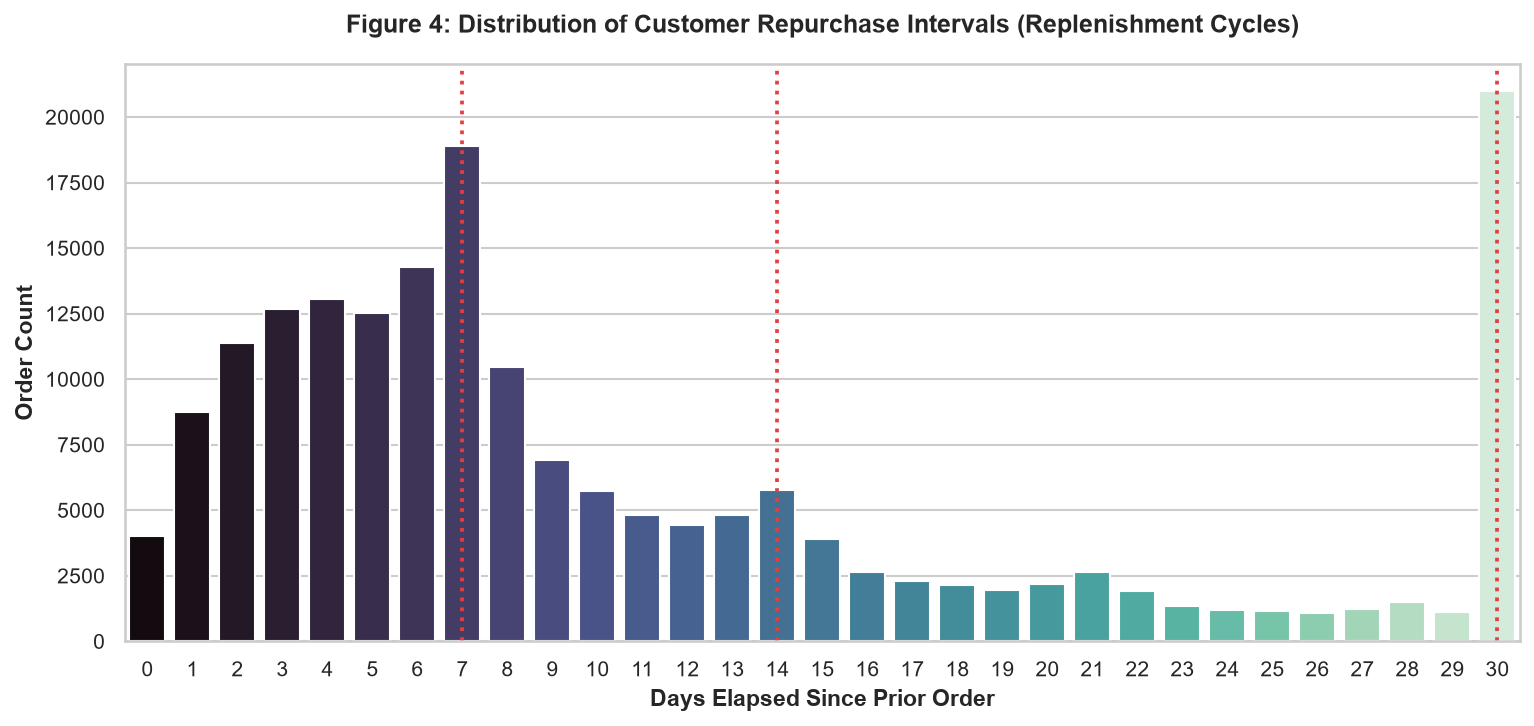

In [34]:
valid_intervals = (
    df_clean.drop_duplicates(subset=["order_id"])
    .query("days_since_prior_order >= 0")["days_since_prior_order"]
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.countplot(x=valid_intervals, palette="mako", ax=ax)

for day_spike, label in [(7, "Weekly (Day 7)"), (14, "Bi-Weekly (Day 14)"), (30, "Monthly Cap (Day 30)")]:
    ax.axvline(x=day_spike, color="#e53e3e", linestyle=":", linewidth=1.8)

ax.set_title("Figure 4: Distribution of Customer Repurchase Intervals (Replenishment Cycles)", pad=15)
ax.set_xlabel("Days Elapsed Since Prior Order", fontweight="bold")
ax.set_ylabel("Order Count", fontweight="bold")

save_figure(fig, "04_reorder_interval_cyclicity.png")
plt.show()

[Exported Figure] -> reports\figures\05_basket_size_distribution.png


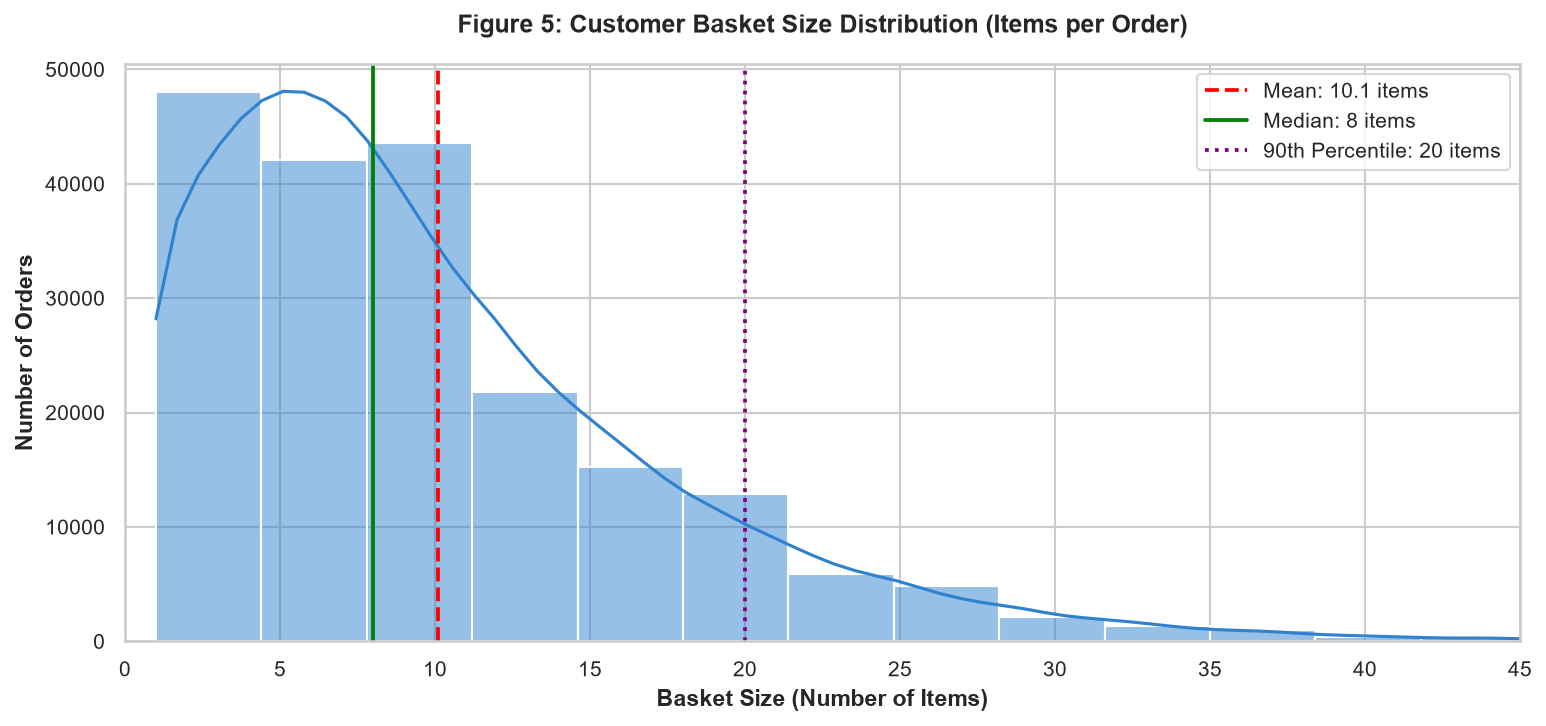

In [35]:
basket_dist = df_clean.drop_duplicates(subset=["order_id"])["basket_size"]

mean_val = basket_dist.mean()
median_val = basket_dist.median()
p90_val = basket_dist.quantile(0.90)

fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(basket_dist, bins=40, kde=True, color="#3182ce", edgecolor="white", ax=ax)

ax.axvline(mean_val, color="red", linestyle="--", linewidth=1.8, label=f"Mean: {mean_val:.1f} items")
ax.axvline(median_val, color="green", linestyle="-", linewidth=1.8, label=f"Median: {median_val:.0f} items")
ax.axvline(p90_val, color="purple", linestyle=":", linewidth=1.8, label=f"90th Percentile: {p90_val:.0f} items")

ax.set_title("Figure 5: Customer Basket Size Distribution (Items per Order)", pad=15)
ax.set_xlabel("Basket Size (Number of Items)", fontweight="bold")
ax.set_ylabel("Number of Orders", fontweight="bold")
ax.set_xlim(0, 45)
ax.legend(fontsize=10)

save_figure(fig, "05_basket_size_distribution.png")
plt.show()

[Exported Figure] -> reports\figures\06_cart_order_vs_reorder_probability.png


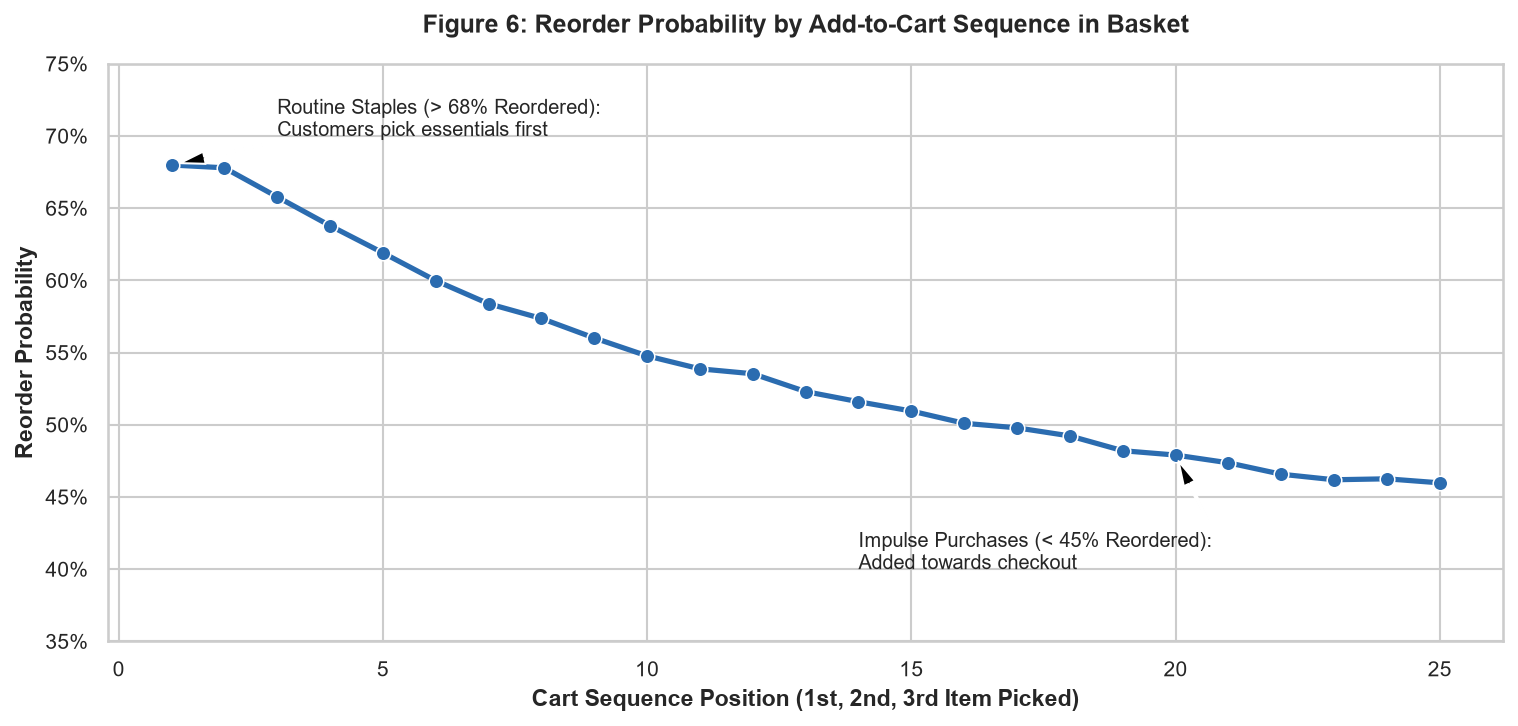

In [36]:
cart_agg = (
    df_clean[df_clean["add_to_cart_order"] <= 25]
    .groupby("add_to_cart_order")
    .agg(reorder_rate=("reordered", "mean"))
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(
    data=cart_agg, x="add_to_cart_order", y="reorder_rate",
    marker="o", color="#2b6cb0", linewidth=2.5, markersize=7, ax=ax
)

ax.set_title("Figure 6: Reorder Probability by Add-to-Cart Sequence in Basket", pad=15)
ax.set_xlabel("Cart Sequence Position (1st, 2nd, 3rd Item Picked)", fontweight="bold")
ax.set_ylabel("Reorder Probability", fontweight="bold")
ax.set_ylim(0.35, 0.75)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y*100:.0f}%"))

ax.annotate(
    "Routine Staples (> 68% Reordered):\nCustomers pick essentials first",
    xy=(1, cart_agg.loc[0, "reorder_rate"]),
    xytext=(3, 0.70),
    arrowprops=dict(facecolor="black", shrink=0.08, width=1, headwidth=6),
    fontsize=9.5
)
ax.annotate(
    "Impulse Purchases (< 45% Reordered):\nAdded towards checkout",
    xy=(20, cart_agg.loc[19, "reorder_rate"]),
    xytext=(14, 0.40),
    arrowprops=dict(facecolor="black", shrink=0.08, width=1, headwidth=6),
    fontsize=9.5
)

save_figure(fig, "06_cart_order_vs_reorder_probability.png")
plt.show()

## 10. Target Class Imbalance Diagnostic Audit & Mitigation Strategy

In [37]:
reorder_counts = df_clean["reordered"].value_counts()
reorder_props = df_clean["reordered"].value_counts(normalize=True) * 100
imbalance_ratio = reorder_counts[1] / reorder_counts[0]

print("TARGET CLASS DISTRIBUTION AUDIT (`reordered`)")
print(f"Class 1 (Reordered / Repeat)  : {reorder_counts[1]:,} ({reorder_props[1]:.2f}%)")
print(f"Class 0 (Acquisition / New)   : {reorder_counts[0]:,} ({reorder_props[0]:.2f}%)")
print(f"Class Ratio (Class 1 : Class 0): {imbalance_ratio:.2f} : 1.00")

TARGET CLASS DISTRIBUTION AUDIT (`reordered`)
Class 1 (Reordered / Repeat)  : 1,190,986 (58.97%)
Class 0 (Acquisition / New)   : 828,515 (41.03%)
Class Ratio (Class 1 : Class 0): 1.44 : 1.00


[Exported Figure] -> reports\figures\07_target_class_balance.png


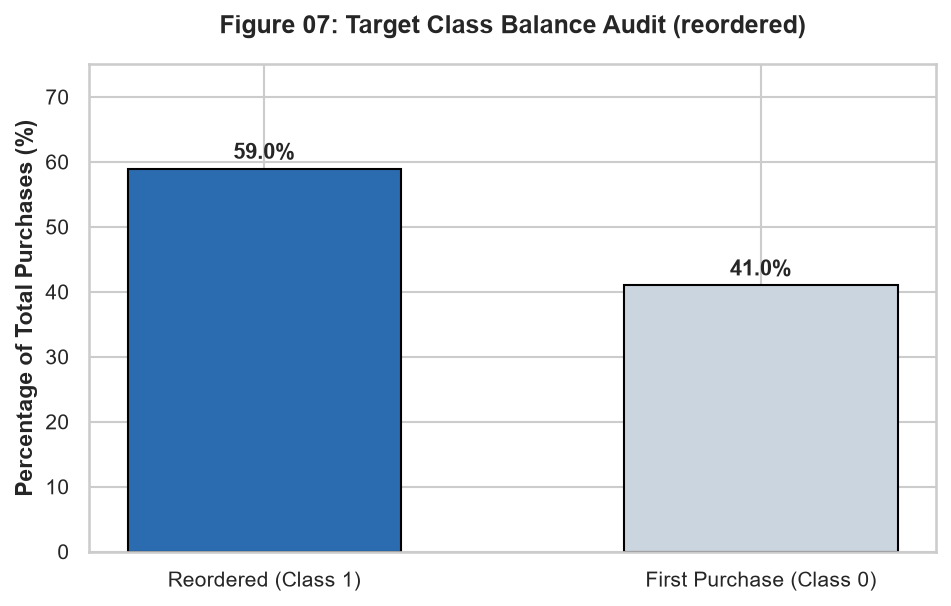

In [38]:
# Figure 07: Target Distribution Bar Chart
fig, ax = plt.subplots(figsize=(6.5, 4.2))
colors = ["#2b6cb0", "#cbd5e0"]
bars = ax.bar(["Reordered (Class 1)", "First Purchase (Class 0)"], [reorder_props[1], reorder_props[0]], color=colors, edgecolor="black", width=0.55)

ax.set_title("Figure 07: Target Class Balance Audit (reordered)", pad=15, fontweight="bold")
ax.set_ylabel("Percentage of Total Purchases (%)", fontweight="bold")
ax.set_ylim(0, 75)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 1.5, f"{height:.1f}%", ha="center", fontweight="bold", fontsize=10.5)

plt.tight_layout()
save_figure(fig, "07_target_class_balance.png")
plt.show()

## 11. Processed Data Persistence & Partitioned Team Handoff Contract
### Handoff Data Contracts:
1. **`cleaned_transactions.parquet` (Full 2,019,501 rows)**:
   * **Consumer**: **Notebook 02 (Obesekara - Market Basket Analysis)**.
   * *Rationale*: Unsupervised association rule mining requires continuous, unfragmented transaction baskets.
2. **`train_transactions.parquet` (80% Stratified - 1,615,600 rows)**:
   * **Consumer**: **Notebook 03 (Peiris - Supervised Model Training)**.
   * *Rationale*: Dedicated training split preserving class balance for feature creation and cross-validation without data leakage.
3. **`test_transactions.parquet` (20% Stratified - 403,901 rows)**:
   * **Consumer**: **Notebook 04 (Weerasooriya - Independent Model Evaluation)**.
   * *Rationale*: Untouched held-out test split for independent evaluation and champion model selection.

In [40]:
from sklearn.model_selection import train_test_split

OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save Full Master Parquet for Member 2 (MBA)
master_parquet = OUTPUT_DIR / "cleaned_transactions.parquet"
df_clean.to_parquet(master_parquet, index=False, engine="pyarrow", compression="snappy")
master_mb = master_parquet.stat().st_size / (1024 ** 2)
print(f" [SAVED] Master Dataset      : {master_parquet.name:<30} ({master_mb:.2f} MB | {len(df_clean):,} rows)")

# 2. Generate Defensive Stratified Split for Member 3 & 4
train_df, test_df = train_test_split(
    df_clean,
    test_size=0.20,
    random_state=42,
    stratify=df_clean["reordered"]
)

train_parquet = OUTPUT_DIR / "train_transactions.parquet"
test_parquet = OUTPUT_DIR / "test_transactions.parquet"

train_df.to_parquet(train_parquet, index=False, engine="pyarrow", compression="snappy")
test_df.to_parquet(test_parquet, index=False, engine="pyarrow", compression="snappy")

print(f" [SAVED] Train Split (80%)   : {train_parquet.name:<30} ({train_parquet.stat().st_size / (1024**2):.2f} MB | {len(train_df):,} rows)")
print(f" [SAVED] Test Split (20%)    : {test_parquet.name:<30} ({test_parquet.stat().st_size / (1024**2):.2f} MB | {len(test_df):,} rows)")

# 3. Export Summary Statistics Table
dept_table = (
    df_clean.groupby("department", observed=False)
    .agg(
        total_items=("product_id", "count"),
        unique_categories=("product_name", "nunique"),
        reorder_rate=("reordered", "mean"),
        avg_cart_position=("add_to_cart_order", "mean")
    )
    .reset_index()
    .sort_values(by="total_items", ascending=False)
)
export_summary_table(dept_table, "eda_summary_statistics.csv")
print(" Summary table exported to reports/tables/eda_summary_statistics.csv")

 [SAVED] Master Dataset      : cleaned_transactions.parquet   (20.51 MB | 2,019,501 rows)
 [SAVED] Train Split (80%)   : train_transactions.parquet     (30.55 MB | 1,615,600 rows)
 [SAVED] Test Split (20%)    : test_transactions.parquet      (8.02 MB | 403,901 rows)
[Exported Table]  -> reports\tables\eda_summary_statistics.csv
 Summary table exported to reports/tables/eda_summary_statistics.csv


## 11. Key Merchandising Takeaways for the Supermarket Owner

1. **The "Staple First" Merchandising Rule**:
   * *Evidence*: Items added to the basket in positions 1–3 have **> 68% reorder rate** (dairy, fresh produce, bread), whereas items added at position 15+ drop to **< 42%**.
   * *Store Placement Action*: Place staple departments (milk, bread, vegetables) toward the rear and perimeter of the physical shop. This guides shoppers through aisles displaying high-margin impulse items (snacks, beverages) that customers pick later.

2. **Weekly & Bi-Weekly Replenishment Rhythm**:
   * *Evidence*: Customer inter-order intervals show sharp recurring spikes at **Day 7** (weekly routine) and **Day 14** (bi-weekly restocking), with peak store checkouts occurring between **10:00 AM – 3:00 PM on Sundays and Mondays**.
   * *Inventory Action*: Schedule major inventory restocking and supplier deliveries on Friday evening and early Sunday morning before customer traffic surges.

3. **High-Velocity Anchor Departments**:
   * *Evidence*: `Produce` (588,996 items) and `Dairy Eggs` (336,915 items) account for **45.8% of all store items sold**, with both showing reorder rates above **65%**.
   * *Merchandising Action*: Treat Dairy and Produce as the store's primary anchor zones. Ensure buffer stock is prioritized here to avoid customer abandonment.